# Setup

In [59]:
import os
import random
import sys
import socket
import platform
from pathlib import Path
from tempfile import TemporaryDirectory
from collections.abc import Sequence

os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import shutil
import zipfile
from tqdm.auto import tqdm

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torch
from torch.utils.data import Dataset
from torch.utils.data import DataLoader


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True)

## Experiment settings

In [60]:
SEED = 67
image_size = None
batch_size = 4
num_workers = 2
architecture = "Unet"
encoder_name = "resnet34"
encoder_lr = 1e-5
decoder_lr = 1e-4
weight_decay = 0.01
epochs = 30
patience = 7
lr_factor = 0.5
lr_patience = 2
weight_limits = (0.5, 5.0)

set_seed(SEED)

In [61]:
IN_COLAB = "COLAB_RELEASE_TAG" in os.environ
DATASET_IMAGE_NAME = "701_StillsRaw_full.zip"
DATASET_LABEL_NAME = "LabeledApproved_full.zip"

if IN_COLAB:
    DATASET_DIR = Path("/content/drive/MyDrive/IF4073_Pemrosesan_Citra_Digital/dataset")
    dataset_root = Path("/content/dataset")
    image_dir = dataset_root / "images"
    label_dir = dataset_root / "labels"
else:
    local_root = Path.cwd()
    if (local_root / "model" / "transfer-learning.ipynb").is_file():
        local_root = local_root / "model"

    DATASET_DIR = local_root / "dataset"
    image_dir = DATASET_DIR / Path(DATASET_IMAGE_NAME).stem
    label_dir = DATASET_DIR / Path(DATASET_LABEL_NAME).stem

## Runtime and dataset setup

In [62]:
print("Hostname:", socket.gethostname())
print("Operating system:", platform.system())
print("Python executable:", sys.executable)
print("Working directory:", os.getcwd())
print("Running in Colab:", IN_COLAB)
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))
else:
    print("No GPU assigned")

Hostname: e3fa6eacf524
Operating system: Linux
Python executable: /usr/bin/python3
Working directory: /content
Running in Colab: True
Tesla T4


In [63]:
if IN_COLAB:
    import gdown

    archives = (
        ("14CRF7mrkHzZjvtVFLnaB0DjejFpRp945", DATASET_IMAGE_NAME, image_dir),
        ("1Nj6b_nSqfGl1W9XKnbXT08ZYDsTl0iTZ", DATASET_LABEL_NAME, label_dir),
    )

    for file_id, archive_name, folder in archives:
        if any(folder.rglob("*.png")):
            continue

        dataset_root.mkdir(parents=True, exist_ok=True)
        with TemporaryDirectory(dir=dataset_root) as temp_dir:
            zip_path = Path(temp_dir) / archive_name
            gdown.download(id=file_id, output=str(zip_path), use_cookies=False)
            if not zipfile.is_zipfile(zip_path):
                raise RuntimeError(f"Could not download {archive_name} as a ZIP.")

            with zipfile.ZipFile(zip_path) as archive:
                archive.extractall(folder)

for folder in (image_dir, label_dir):
    if not any(folder.rglob("*.png")):
        raise FileNotFoundError(f"No PNG files found in {folder}")
    print(f"Using {folder}")

Using /content/dataset/images
Using /content/dataset/labels


# Preprocessing

In [64]:
images = sorted(image_dir.rglob("*.png"))
if not images:
    raise FileNotFoundError(f"No PNG images found in {image_dir}")

pairs = [(image, label_dir / f"{image.stem}_L.png") for image in images]
for _, mask_path in pairs:
    if not mask_path.is_file():
        raise FileNotFoundError(f"Missing mask: {mask_path}")

In [67]:
# CamVid's annotation colors as (red, green, blue) tuples.
CAMVID_CLASSES = {
    (64, 128, 64): "Animal",
    (192, 0, 128): "Archway",
    (0, 128, 192): "Bicyclist",
    (0, 128, 64): "Bridge",
    (128, 0, 0): "Building",
    (64, 0, 128): "Car",
    (64, 0, 192): "CartLuggagePram",
    (192, 128, 64): "Child",
    (192, 192, 128): "Column_Pole",
    (64, 64, 128): "Fence",
    (128, 0, 192): "LaneMkgsDriv",
    (192, 0, 64): "LaneMkgsNonDriv",
    (128, 128, 64): "Misc_Text",
    (192, 0, 192): "MotorcycleScooter",
    (128, 64, 64): "OtherMoving",
    (64, 192, 128): "ParkingBlock",
    (64, 64, 0): "Pedestrian",
    (128, 64, 128): "Road",
    (128, 128, 192): "RoadShoulder",
    (0, 0, 192): "Sidewalk",
    (192, 128, 128): "SignSymbol",
    (128, 128, 128): "Sky",
    (64, 128, 192): "SUVPickupTruck",
    (0, 0, 64): "TrafficCone",
    (0, 64, 64): "TrafficLight",
    (192, 64, 128): "Train",
    (128, 128, 0): "Tree",
    (192, 128, 192): "Truck_Bus",
    (64, 0, 64): "Tunnel",
    (192, 192, 0): "VegetationMisc",
    (0, 0, 0): "Void",
    (64, 192, 0): "Wall",
}

# CamVid-11 groups in model output order. The first member supplies the display color.
class_groups = {
    "Sky": ("Sky",),
    "Building": ("Building", "Bridge", "Wall", "Tunnel", "Archway"),
    "Pole": ("Column_Pole", "TrafficCone"),
    "Road": ("Road", "LaneMkgsDriv", "LaneMkgsNonDriv"),
    "Pavement": ("Sidewalk", "ParkingBlock", "RoadShoulder"),
    "Tree": ("Tree", "VegetationMisc"),
    "SignSymbol": ("SignSymbol", "Misc_Text", "TrafficLight"),
    "Fence": ("Fence",),
    "Car": ("Car", "SUVPickupTruck", "Truck_Bus", "Train", "OtherMoving"),
    "Pedestrian": ("Pedestrian", "Child", "CartLuggagePram", "Animal"),
    "Bicyclist": ("Bicyclist", "MotorcycleScooter"),
}
IGNORE_INDEX = 255
class_names = list(class_groups)
num_classes = len(class_names)
rgb_by_name = {name: rgb for rgb, name in CAMVID_CLASSES.items()}
class_colors = [rgb_by_name[members[0]] for members in class_groups.values()]
color_to_class = {}
for class_id, members in enumerate(class_groups.values()):
    for name in members:
        red, green, blue = rgb_by_name[name]
        color_to_class[(red << 16) | (green << 8) | blue] = class_id


def load_mask(mask_path: str | Path) -> np.ndarray[np.uint8]:
    mask_path = Path(mask_path)
    with Image.open(mask_path) as mask:
        rgb = np.asarray(mask.convert("RGB"), dtype=np.uint32)

    red, green, blue = rgb[..., 0], rgb[..., 1], rgb[..., 2]
    colors = (red << 16) | (green << 8) | blue

    target = np.full(colors.shape, IGNORE_INDEX, dtype=np.uint8)
    for color, class_id in color_to_class.items():
        target[colors == color] = class_id


    return target


print(f"Found {len(pairs)} image–mask pairs.")

print("Test image:")
_, mask_path = pairs[0]
target = load_mask(mask_path)
class_ids = np.unique(target[target != IGNORE_INDEX])
print(f"    Classes in {Path(mask_path).name}: {[class_names[i] for i in class_ids]}")
print(f"    Ignored pixels: {np.count_nonzero(target == IGNORE_INDEX)}")

Found 701 image–mask pairs.
Test image:
    Classes in 0001TP_006690_L.png: ['Sky', 'Building', 'Pole', 'Road', 'Pavement', 'Tree', 'SignSymbol', 'Car', 'Pedestrian']
    Ignored pixels: 28603


Images in a sequence (video) belong in one split. 

In [68]:
class CamVidDataset(Dataset):
    def __init__(
        self,
        pairs: Sequence[tuple[Path, Path]],
        image_size: tuple[int, int] | None = None,
    ) -> None:
        self.pairs = pairs
        self.image_size = image_size  # (height, width)
        self.mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
        self.std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]

    def __len__(self) -> int:
        return len(self.pairs)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        image_path, mask_path = self.pairs[index]

        with Image.open(image_path) as source:
            image = source.convert("RGB")
        mask = load_mask(mask_path)

        if self.image_size is not None: # then resize
            height, width = self.image_size
            size = (width, height)  # Pillow takes (width, height).
            image = image.resize(size, Image.Resampling.BILINEAR)
            mask = np.array(Image.fromarray(mask).resize(size, Image.Resampling.NEAREST))

        image_tensor = torch.from_numpy(np.array(image)).permute(2, 0, 1)
        image_tensor = (image_tensor.float() / 255.0 - self.mean) / self.std
        target = torch.from_numpy(mask.astype(np.int64))

        return image_tensor, target


image, target = CamVidDataset(pairs)[0]
print(image.shape, image.dtype)
print(target.shape, target.dtype)

torch.Size([3, 720, 960]) torch.float32
torch.Size([720, 960]) torch.int64


In [69]:
sequence_to_split = {
    "0016E5": "train",
    "Seq05VD": "train",
    "0001TP": "validation",
    "0006R0": "test",
}

splits = {"train": [], "validation": [], "test": []}
for image_path, mask_path in pairs:
    sequence = image_path.stem.split("_", 1)[0]
    splits[sequence_to_split[sequence]].append((image_path, mask_path))

loaders = {}
for split, split_pairs in splits.items():
    loaders[split] = DataLoader(
        CamVidDataset(split_pairs, image_size=image_size),
        batch_size=batch_size,
        shuffle=(split == "train"),
        num_workers=num_workers,
        pin_memory=torch.cuda.is_available(),
    )
    print(f"{split}: {len(split_pairs)} images")

train_loader = loaders["train"]
validation_loader = loaders["validation"]
test_loader = loaders["test"]

train: 476 images
validation: 124 images
test: 101 images


# EDA

In [ ]:
def class_coverage(split_pairs):
    frame_counts = np.zeros(num_classes, dtype=np.int64)
    pixel_counts = np.zeros(num_classes, dtype=np.int64)
    sequences = [set() for _ in class_names]

    for image_path, mask_path in split_pairs:
        target = load_mask(mask_path)
        # Keep only the grouped classes and drop the ignore index.
        counts = np.bincount(target.ravel(), minlength=num_classes)[:num_classes]
        frame_counts += counts > 0
        pixel_counts += counts

        sequence = image_path.stem.split("_", 1)[0]
        for class_id in np.flatnonzero(counts):
            sequences[class_id].add(sequence)

    return frame_counts, pixel_counts, sequences


train_frames, train_pixels, train_sequences = class_coverage(splits["train"])
val_frames, _, _ = class_coverage(splits["validation"])
train_pixel_share = 100 * train_pixels / train_pixels.sum()

print(f"{'Class':20s} {'Train frames':>12s} {'Train pixels %':>14s} ", f"{'Train videos':>12s} {'Val frames':>10s}")
for i in np.argsort(train_frames):
    print(f"{class_names[i]:20s} {train_frames[i]:12d} {train_pixel_share[i]:14.5f} ", f"{len(train_sequences[i]):12d} {val_frames[i]:10d}")

# Fine-tuning

In [70]:
if IN_COLAB:
    import subprocess

    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "segmentation-models-pytorch==0.5.0"],
        check=True,
    )

## Model and optimizer setup

In [71]:
import segmentation_models_pytorch as smp

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"

def build_model():
    set_seed(SEED)
    constructor = {"DeepLabV3Plus": smp.DeepLabV3Plus, "Unet": smp.Unet}[architecture]
    model = constructor(
        encoder_name=encoder_name, encoder_weights="imagenet",
        in_channels=3, classes=num_classes, activation=None,
    ).to(device)
    model.encoder.requires_grad_(False)
    model.encoder.layer4.requires_grad_(True)
    model.encoder.layer3.requires_grad_(True)
    optimizer = torch.optim.AdamW([
        {"params": model.encoder.layer4.parameters(), "lr": encoder_lr},
        {"params": model.encoder.layer3.parameters(), "lr": encoder_lr},
        {"params": model.decoder.parameters(), "lr": decoder_lr},
        {"params": model.segmentation_head.parameters(), "lr": decoder_lr},
    ], weight_decay=weight_decay)
    return model, optimizer

## Loss and training functions

In [72]:
def count_class_weights(loader: DataLoader) -> torch.Tensor:
    counts = torch.zeros(num_classes, dtype=torch.int64)
    for _, targets in tqdm(loader, desc="Counting training pixels"):
        labeled = targets[targets != IGNORE_INDEX]
        counts += torch.bincount(labeled.cpu(), minlength=num_classes)
    pixel_counts = counts.numpy()
    present = pixel_counts > 0
    if not present.any():
        raise ValueError("The training loader contains no labeled pixels.")
    weights = np.ones(num_classes)
    weights[present] = np.sqrt(np.median(pixel_counts[present]) / pixel_counts[present])
    weights = np.clip(weights, *weight_limits)
    weights /= np.average(weights, weights=pixel_counts)
    return torch.tensor(weights, dtype=torch.float32, device=device)


def criterion(logits, targets, class_weights=None):
    valid = targets != IGNORE_INDEX
    safe_targets = targets.masked_fill(~valid, 0)
    log_probs = logits.float().log_softmax(dim=1)
    pixel_loss = -log_probs.gather(1, safe_targets.unsqueeze(1)).squeeze(1)
    if class_weights is not None:
        pixel_loss = pixel_loss * class_weights[safe_targets]
    return pixel_loss.masked_fill(~valid, 0).sum() / valid.sum().clamp_min(1)

In [73]:
def run_epoch(model, loader: DataLoader, *, optimizer=None, scaler=None, class_weights=None) -> float:
    training = optimizer is not None
    model.train(training)
    if training:  # Preserve pretrained encoder BatchNorm statistics.
        model.encoder.eval()
    total_loss = torch.zeros((), device=device)
    total_pixels = torch.zeros((), dtype=torch.long, device=device)

    with torch.set_grad_enabled(training):
        for images, targets in tqdm(loader, desc="Train" if training else "Validation"):
            images = images.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)

            if training:
                optimizer.zero_grad(set_to_none=True)

            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                logits = model(images)
                loss = criterion(logits, targets, class_weights)

            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            valid_pixels = (targets != IGNORE_INDEX).sum()
            total_loss += loss.detach() * valid_pixels
            total_pixels += valid_pixels

    return (total_loss / total_pixels).item()

In [74]:
def fit(model, optimizer, train_loader: DataLoader, validation_loader: DataLoader | None,
        *, epochs: int, checkpoint_path: Path, lr_history=None):
    weights = count_class_weights(train_loader)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=lr_factor, patience=lr_patience
    )
    checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
    best_loss = float("inf")
    best_epoch = 0
    history = []

    for epoch in range(1, epochs + 1):
        set_seed(SEED + epoch)
        if lr_history is not None:
            for group, lr in zip(optimizer.param_groups, lr_history[epoch - 1], strict=True):
                group["lr"] = lr
        learning_rates = [group["lr"] for group in optimizer.param_groups]
        train_loss = run_epoch(model, train_loader, optimizer=optimizer,
                               scaler=scaler, class_weights=weights)
        validation_loss = None
        save_model = epoch == epochs
        message = f"Epoch {epoch}/{epochs} | train {train_loss:.4f}"
        if validation_loader is not None:
            validation_loss = run_epoch(model, validation_loader)
            scheduler.step(validation_loss)
            save_model = validation_loss < best_loss
            if save_model:
                best_loss, best_epoch = validation_loss, epoch
            message += f" | val {validation_loss:.4f}"
        history.append(dict(epoch=epoch, train_loss=train_loss, validation_loss=validation_loss,
                            learning_rates=learning_rates))
        print(message)

        if save_model:
            state = dict(model=model.state_dict(), epoch=epoch, validation_loss=validation_loss,
                         architecture=architecture, encoder_name=encoder_name, class_names=class_names)
            temporary = checkpoint_path.with_suffix(".tmp")
            torch.save(state, temporary)
            temporary.replace(checkpoint_path)
        if validation_loader is not None and epoch - best_epoch >= patience:
            print(f"Early stopping. Best epoch was {best_epoch}.")
            break
    return history

## Train

In [ ]:
from tempfile import mkdtemp

checkpoint_root = Path(DATASET_DIR).parent / "checkpoints"
checkpoint_root.mkdir(parents=True, exist_ok=True)
run_dir = Path(mkdtemp(prefix=f"camvid11-{architecture}-{encoder_name}-", dir=checkpoint_root))
best_path = run_dir / "best.pt"
print(f"Saving model to {best_path}")

model, optimizer = build_model()
history = fit(model, optimizer, train_loader, validation_loader, epochs=epochs, checkpoint_path=best_path)

# Test

Retrain on train + val

In [75]:
final_epochs = 5

combined_loader = DataLoader(
    CamVidDataset(splits["train"] + splits["validation"], image_size=image_size),
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=(device.type == "cuda"),
)

run_dir = Path(DATASET_DIR).parent / "checkpoints" / f"camvid11-{architecture}-{encoder_name}"
run_dir.mkdir(parents=True, exist_ok=True)
final_path = run_dir / "final.pt"

model, optimizer = build_model()
fit(
    model,
    optimizer,
    train_loader=combined_loader,
    validation_loader=None,
    epochs=final_epochs,
    checkpoint_path=final_path,
)

print(f"Saved model to {final_path}")

Counting training pixels:   0%|          | 0/150 [00:00<?, ?it/s]

Train:   0%|          | 0/150 [00:00<?, ?it/s]

Epoch 1/5 | train 1.3160


Train:   0%|          | 0/150 [00:00<?, ?it/s]

Epoch 2/5 | train 0.6756


Train:   0%|          | 0/150 [00:00<?, ?it/s]

... (2 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cac936bf6a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cac936bf6a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 4/5 | train 0.3552


Train:   0%|          | 0/150 [00:00<?, ?it/s]

Epoch 5/5 | train 0.2826
Saved model to /content/drive/MyDrive/IF4073_Pemrosesan_Citra_Digital/checkpoints/camvid11-Unet-resnet34/final.pt


In [76]:
checkpoint = torch.load(final_path, map_location="cpu", weights_only=True)
model.load_state_dict(checkpoint["model"])
print(f"Evaluating epoch {checkpoint['epoch']}")
del checkpoint

model.eval()
confusion = torch.zeros(
    (num_classes, num_classes), dtype=torch.long, device=device
)

with torch.inference_mode():
    for images, targets in tqdm(test_loader, desc="Test"):
        images = images.to(device)
        targets = targets.to(device)

        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            predictions = model(images).argmax(dim=1)

        valid = targets != IGNORE_INDEX
        # Rows are true classes. Columns are predicted classes.
        indices = targets[valid] * num_classes + predictions[valid]
        confusion += torch.bincount(
            indices, minlength=num_classes ** 2
        ).reshape(num_classes, num_classes)

confusion = confusion.cpu()
correct = confusion.diag()
actual = confusion.sum(dim=1)
predicted = confusion.sum(dim=0)
union = actual + predicted - correct
included = union > 0

iou = correct / union.clamp_min(1)
dice = 2 * correct / (actual + predicted).clamp_min(1)
precision = correct / predicted.clamp_min(1)
recall = correct / actual.clamp_min(1)

print(f"Pixel accuracy: {correct.sum() / confusion.sum():.2%}")
print(f"Mean IoU:       {iou[included].mean():.2%}")
print(f"Mean Dice:      {dice[included].mean():.2%}")
print(f"Mean precision: {precision[included].mean():.2%}")
print(f"Mean recall:    {recall[included].mean():.2%}")

print("\nPer-class IoU")
for name, score, present in zip(class_names, iou, included):
    if present:
        print(f"{name:20s} {score:.2%}")

Evaluating epoch 5


Test:   0%|          | 0/26 [00:00<?, ?it/s]

Pixel accuracy: 86.73%
Mean IoU:       50.59%
Mean Dice:      62.00%
Mean precision: 60.29%
Mean recall:    65.95%

Per-class IoU
Sky                  88.39%
Building             66.10%
Pole                 30.57%
Road                 89.19%
Pavement             28.00%
Tree                 76.63%
SignSymbol           38.12%
Fence                18.84%
Car                  75.51%
Pedestrian           43.25%
Bicyclist            1.87%


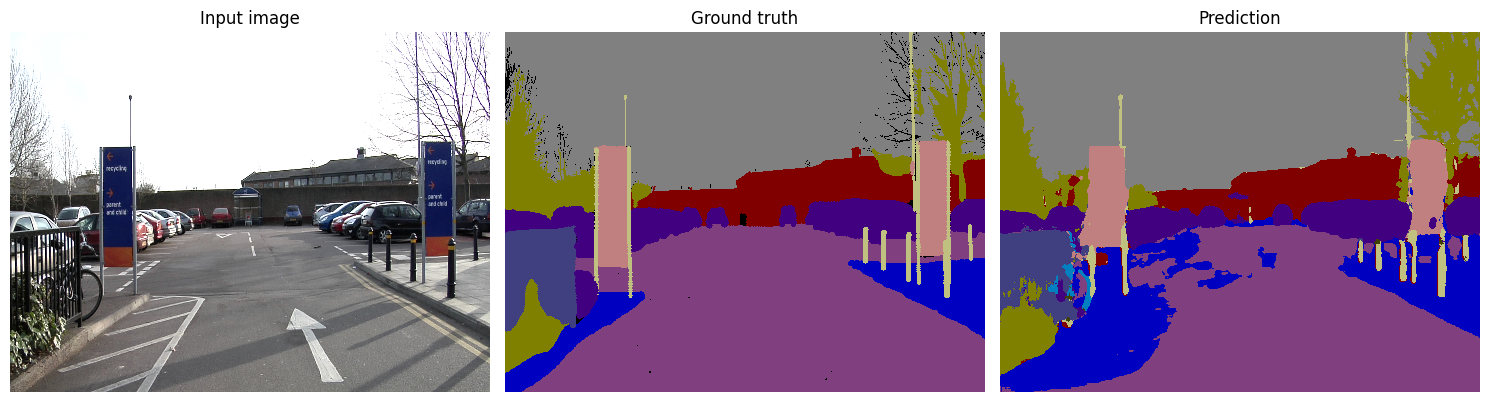

In [77]:
sample_index = 100
test_dataset = test_loader.dataset
image, target = test_dataset[sample_index]

model.eval()
with torch.inference_mode():
    with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
        logits = model(image.unsqueeze(0).to(device))
    prediction = logits.argmax(dim=1)[0].cpu().numpy()

# Undo ImageNet normalization for display.
rgb = (image * test_dataset.std + test_dataset.mean).clamp(0, 1)
rgb = rgb.permute(1, 2, 0).numpy()

# Map class IDs back to RGB. The ignore index stays black.
palette = np.zeros((256, 3), dtype=np.uint8)
palette[:num_classes] = class_colors

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, title, pixels in zip(
    axes,
    ("Input image", "Ground truth", "Prediction"),
    (rgb, palette[target.numpy()], palette[prediction]),
):
    ax.imshow(pixels, interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()